In [1]:

import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import precision_score, recall_score, f1_score





In [2]:
df= pd.read_csv("C:/Users/shrid/Downloads/mlpractice/data.csv",header = None)
df.head()
df.columns = [
    "id", "diagnosis","radius_mean", "texture_mean", "perimeter_mean", "area_mean",
    "smoothness_mean", "compactness_mean", "concavity_mean",
    "concave_points_mean", "symmetry_mean", "fractal_dimension_mean",
    "radius_se", "texture_se", "perimeter_se", "area_se",
    "smoothness_se", "compactness_se", "concavity_se",
    "concave_points_se", "symmetry_se", "fractal_dimension_se",
    "radius_worst", "texture_worst", "perimeter_worst", "area_worst",
    "smoothness_worst", "compactness_worst", "concavity_worst",
    "concave_points_worst", "symmetry_worst", "fractal_dimension_worst"
]

In [3]:
df

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,927241,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,...,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400


In [4]:
df = df.drop(columns=["id"])

In [5]:
df.duplicated().sum()

np.int64(0)

In [6]:
df.isna().sum()

diagnosis                  0
radius_mean                0
texture_mean               0
perimeter_mean             0
area_mean                  0
smoothness_mean            0
compactness_mean           0
concavity_mean             0
concave_points_mean        0
symmetry_mean              0
fractal_dimension_mean     0
radius_se                  0
texture_se                 0
perimeter_se               0
area_se                    0
smoothness_se              0
compactness_se             0
concavity_se               0
concave_points_se          0
symmetry_se                0
fractal_dimension_se       0
radius_worst               0
texture_worst              0
perimeter_worst            0
area_worst                 0
smoothness_worst           0
compactness_worst          0
concavity_worst            0
concave_points_worst       0
symmetry_worst             0
fractal_dimension_worst    0
dtype: int64

In [7]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df["diagnosis"] = le.fit_transform(df["diagnosis"])

df.head()

X = df.drop("diagnosis",axis=1)
y = df["diagnosis"]

In [8]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [9]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [10]:
svm_model = SVC()
svm_model.fit(X_train_scaled, y_train)

svm_cv_scores = cross_val_score(
    svm_model,
    X_train_scaled,
    y_train,
    cv=5,
    scoring="accuracy"
)

In [11]:
print("\nSVM Cross-Validation Scores:")
print(svm_cv_scores)

print("Mean SVM CV Accuracy:", svm_cv_scores.mean())

svm_model.fit(X_train_scaled, y_train)

svm_pred = svm_model.predict(X_test_scaled)

svm_accuracy = accuracy_score(y_test, svm_pred)
svm_precision = precision_score(y_test, svm_pred)
svm_recall = recall_score(y_test, svm_pred)
svm_f1 = f1_score(y_test, svm_pred)

print("\nSVM Before Optimization")
print("Accuracy:", svm_accuracy)
print("Precision:", svm_precision)
print("Recall:", svm_recall)
print("F1 Score:", svm_f1)


SVM Cross-Validation Scores:
[0.97802198 0.96703297 0.98901099 0.98901099 0.95604396]
Mean SVM CV Accuracy: 0.9758241758241759

SVM Before Optimization
Accuracy: 0.9824561403508771
Precision: 1.0
Recall: 0.9534883720930233
F1 Score: 0.9761904761904762


After grid search


In [12]:
svm_param_grid = {
    "C": [0.1, 1, 10, 100],
    "kernel": ["linear", "rbf"],
    "gamma": ["scale", "auto"]
}

svm_grid = GridSearchCV(
    estimator=SVC(),
    param_grid=svm_param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

svm_grid.fit(X_train_scaled, y_train)

print("\nSVM Best Parameters:")
print(svm_grid.best_params_)

print("SVM Best Cross-Validation Accuracy:")
print(svm_grid.best_score_)

best_svm = svm_grid.best_estimator_

best_svm_pred = best_svm.predict(X_test_scaled)

best_svm_accuracy = accuracy_score(y_test, best_svm_pred)
best_svm_precision = precision_score(y_test, best_svm_pred)
best_svm_recall = recall_score(y_test, best_svm_pred)
best_svm_f1 = f1_score(y_test, best_svm_pred)

print("\nSVM After Optimization")
print("Accuracy:", best_svm_accuracy)
print("Precision:", best_svm_precision)
print("Recall:", best_svm_recall)
print("F1 Score:", best_svm_f1)


SVM Best Parameters:
{'C': 1, 'gamma': 'scale', 'kernel': 'rbf'}
SVM Best Cross-Validation Accuracy:
0.9758241758241759

SVM After Optimization
Accuracy: 0.9824561403508771
Precision: 1.0
Recall: 0.9534883720930233
F1 Score: 0.9761904761904762


random forest

In [13]:
rf = RandomForestClassifier(random_state=42)

rf_cv_scores = cross_val_score(
    rf,
    X_train,
    y_train,
    cv=5,
    scoring="accuracy"
)

print("\nRandom Forest Cross-Validation Scores:")
print(rf_cv_scores)

print("Mean RF CV Accuracy:", rf_cv_scores.mean())

rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)
rf_accuracy = accuracy_score(y_test, rf_pred)
rf_precision = precision_score(y_test, rf_pred)
rf_recall = recall_score(y_test, rf_pred)
rf_f1 = f1_score(y_test, rf_pred)

print("\nRandom Forest Before Optimization")
print("Accuracy:", rf_accuracy)
print("Precision:", rf_precision)
print("Recall:", rf_recall)
print("F1 Score:", rf_f1)


Random Forest Cross-Validation Scores:
[0.96703297 0.94505495 0.97802198 0.95604396 0.93406593]
Mean RF CV Accuracy: 0.956043956043956

Random Forest Before Optimization
Accuracy: 0.9649122807017544
Precision: 0.975609756097561
Recall: 0.9302325581395349
F1 Score: 0.9523809523809523


after grid search

In [14]:
rf_param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 5, 10]
}

rf_grid = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=rf_param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

rf_grid.fit(X_train, y_train)

print("Random Forest Best Parameters:")
print(rf_grid.best_params_)

print("Random Forest Best Cross-Validation Accuracy:")
print(rf_grid.best_score_)

best_rf = rf_grid.best_estimator_

best_rf_pred = best_rf.predict(X_test)

best_rf_accuracy = accuracy_score(y_test, best_rf_pred)
best_rf_precision = precision_score(y_test, best_rf_pred)
best_rf_recall = recall_score(y_test, best_rf_pred)
best_rf_f1 = f1_score(y_test, best_rf_pred)

print("Random Forest After Optimization")
print("Accuracy:", best_rf_accuracy)
print("Precision:", best_rf_precision)
print("Recall:", best_rf_recall)
print("F1 Score:", best_rf_f1)

Random Forest Best Parameters:
{'max_depth': None, 'n_estimators': 200}
Random Forest Best Cross-Validation Accuracy:
0.9626373626373625
Random Forest After Optimization
Accuracy: 0.9649122807017544
Precision: 0.975609756097561
Recall: 0.9302325581395349
F1 Score: 0.9523809523809523


**ada boost before **

In [15]:
ada_b = AdaBoostClassifier(random_state=42)

ada_cv_scores = cross_val_score(
    ada_b,
    X_train,
    y_train,
    cv=5,
    scoring="accuracy"
)

print("\nAdaBoost Cross-Validation Scores:")
print(ada_cv_scores)

print("Mean AdaBoost CV Accuracy:", ada_cv_scores.mean())

ada_b.fit(X_train, y_train)
ada_pred = ada_b.predict(X_test)
ada_accuracy = accuracy_score(y_test, ada_pred)
ada_precision = precision_score(y_test, ada_pred)
ada_recall = recall_score(y_test, ada_pred)
ada_f1 = f1_score(y_test, ada_pred)

print("\nAdaBoost Before Optimization")
print("Accuracy:", ada_accuracy)
print("Precision:", ada_precision)
print("Recall:", ada_recall)
print("F1 Score:", ada_f1)


AdaBoost Cross-Validation Scores:
[0.97802198 0.97802198 1.         0.97802198 0.96703297]
Mean AdaBoost CV Accuracy: 0.9802197802197803

AdaBoost Before Optimization
Accuracy: 0.9649122807017544
Precision: 0.975609756097561
Recall: 0.9302325581395349
F1 Score: 0.9523809523809523


In [16]:
ada_param_grid = {
    "n_estimators": [50, 100, 200],
    "learning_rate": [0.01, 0.1, 1.0]
}

ada_grid = GridSearchCV(
    estimator=AdaBoostClassifier(random_state=42),
    param_grid=ada_param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

ada_grid.fit(X_train, y_train)

print("\nAdaBoost Best Parameters:")
print(ada_grid.best_params_)

print("AdaBoost Best Cross-Validation Accuracy:")
print(ada_grid.best_score_)

best_ada = ada_grid.best_estimator_

best_ada_pred = best_ada.predict(X_test)

best_ada_accuracy = accuracy_score(y_test, best_ada_pred)
best_ada_precision = precision_score(y_test, best_ada_pred)
best_ada_recall = recall_score(y_test, best_ada_pred)
best_ada_f1 = f1_score(y_test, best_ada_pred)

print("\nAdaBoost After Optimization")
print("Accuracy:", best_ada_accuracy)
print("Precision:", best_ada_precision)
print("Recall:", best_ada_recall)
print("F1 Score:", best_ada_f1)


AdaBoost Best Parameters:
{'learning_rate': 1.0, 'n_estimators': 50}
AdaBoost Best Cross-Validation Accuracy:
0.9802197802197803

AdaBoost After Optimization
Accuracy: 0.9649122807017544
Precision: 0.975609756097561
Recall: 0.9302325581395349
F1 Score: 0.9523809523809523


               Before Optimization  After Optimization
SVM                      98.245614           98.245614
Random Forest            96.491228           96.491228
AdaBoost                 96.491228           96.491228


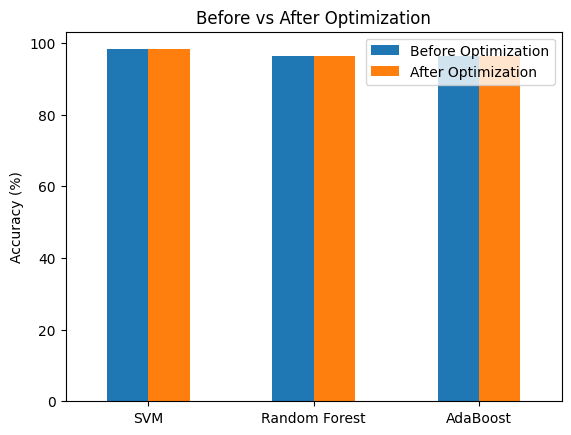

In [17]:

import pandas as pd
import matplotlib.pyplot as plt

results = pd.DataFrame({
    "Before Optimization": [svm_accuracy, rf_accuracy, ada_accuracy],
    "After Optimization": [best_svm_accuracy, best_rf_accuracy, best_ada_accuracy]
}, index=["SVM", "Random Forest", "AdaBoost"])

print(results * 100)

(results * 100).plot(kind="bar")

plt.ylabel("Accuracy (%)")
plt.title("Before vs After Optimization")
plt.xticks(rotation=0)
plt.show()

In [ ]:
feature_names = X.columns

user_input = []

for feature in feature_names:
    value = float(input(f"Enter {feature}: "))
    user_input.append(value)


input_df = pd.DataFrame([user_input], columns=feature_names)

input_scaled = scaler.transform(input_df)



In [ ]:
p_ada = best_ada.predict(input_scaled)

if p_ada[0] == 0 :
  print('diagonsed B')
else:
  print('diagonsed M')

In [ ]:
p_svm= best_svm.predict(input_scaled)

if p_svm[0] == 0 :
  print('diagonsed B')
else:
  print('diagonsed M')

In [ ]:
p_rf= best_rf.predict(input_scaled)

if p_rf[0] == 0 :
  print('diagonsed B')
else:
  print('diagonsed M')